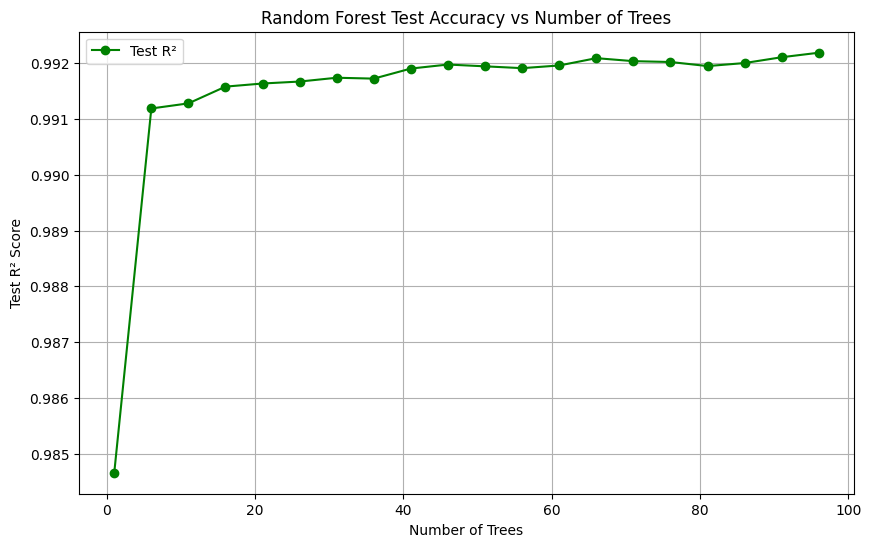

In [17]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

# --- Load dataset ---
df = pd.read_csv("dataset.csv")

# --- Clean numeric columns ---
numeric_cols = ["Dose_Gy", "Avg_Temp_C", "Rainfall_mm", "Growth_Days", "Yield_kg_per_acre"]
for col in numeric_cols:
    df[col] = df[col].astype(str).str.replace(",", "").astype(float)

# --- Fill missing categorical columns ---
categorical_features = ["Crop", "Radiation_Type", "Mutation_Trait", "Location", "Soil_Type"]
df['Radiation_Type'] = df['Radiation_Type'].fillna("None")
df['Mutation_Trait'] = df['Mutation_Trait'].fillna("None")

# --- One-Hot Encode categorical features ---
df_encoded = pd.get_dummies(df, columns=categorical_features)

# --- Split dataset ---
X = df_encoded.drop("Yield_kg_per_acre", axis=1)
y = df_encoded["Yield_kg_per_acre"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Evaluate test accuracy over number of trees ---
n_trees = range(1, 101, 5)  # 1 to 100 trees, step 5
test_r2 = []

for n in n_trees:
    rf = RandomForestRegressor(n_estimators=n, random_state=42)
    rf.fit(X_train, y_train)
    test_r2.append(r2_score(y_test, rf.predict(X_test)))

# --- Plot only test R² ---
plt.figure(figsize=(10,6))
plt.plot(n_trees, test_r2, label="Test R²", marker='o', color='green')
plt.xlabel("Number of Trees")
plt.ylabel("Test R² Score")
plt.title("Random Forest Test Accuracy vs Number of Trees")
plt.legend()
plt.grid(True)
plt.show()
